In [1]:
#Importamos las librerías que vamos a utilizar
from IPython.display import HTML
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis, shapiro, kendalltau

import xgboost as xgb

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV


from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score
)

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression

# Escribimos una función para limpiar los nombres de las columnas, elimina [] y espacios y los reemplaza con _
def limpiar_nombres_columnas(df):
    df = df.copy()
    df.columns = [
        re.sub(r"[\[\]<>]", "", str(col))
        .strip()
        .replace(" ", "_")
        for col in df.columns
    ]
    return df

In [2]:
ruta = r"Material/Datasets/ai4i2020.csv"
df = pd.read_csv(ruta)

# Aplicamos la limpieza
df = limpiar_nombres_columnas(df)

In [3]:
# Mostramos la cantidad de filas y columnas del DataFrame
print("El DataFrame tiene", df.shape[0], "filas y", df.shape[1] ,"columnas")


El DataFrame tiene 10000 filas y 14 columnas


In [34]:
# Mostramos las primeras filas del DataFrame
df.head()


,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [37]:
# Eliminamos las variables UDI y Product_ID
df.drop(columns=['UDI', 'Product_ID'], inplace=True)

In [38]:
# Creamos un nuevo DataFrame para juntar informaciones
info_df = pd.DataFrame({
    'Tipo de Dato': df.dtypes,
    'Valores Nulos': df.isnull().sum(),
})

# Asignamos un nombre a la primera columna del DataFrame
info_df = info_df.reset_index().rename(columns={'index': 'Variables'})

info_df


,Variables,Tipo de Dato,Valores Nulos
0,Type,object,0
1,Air_temperature_K,float64,0
2,Process_temperature_K,float64,0
3,Rotational_speed_rpm,int64,0
4,Torque_Nm,float64,0
5,Tool_wear_min,int64,0
6,Machine_failure,int64,0
7,TWF,int64,0
8,HDF,int64,0
9,PWF,int64,0


In [39]:
# Generamos las estadísticas descriptivas del DataFrame
df.describe()


,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


### 🔍 Diagnóstico del Balance de Clases 



In [40]:
# Vamos a ver la cantidad de fallas que hay en el dataset
conteo_fallas = df['Machine_failure'].value_counts()

# Calculamos el porcentaje de fallas en el dataset
porcentaje_fallas = df['Machine_failure'].value_counts(normalize=True) * 100

# Resumen 
resumen_fallas = pd.DataFrame({
    'Cantidad de fallas' : conteo_fallas,
    'Porcentaje (%)' : porcentaje_fallas.round(4)
})

resumen_fallas.index.name = None

resumen_fallas


,Cantidad de fallas,Porcentaje (%)
0,9661,96.61
1,339,3.39


A partir del análisis cuantitativo de la variable objetivo `Machine_failure`, se extraen las siguientes conclusiones analíticas fundamentales para el desarrollo del modelo:

* **Predominancia de la Clase Mayoritaria:** El **96.61%** de los registros históricos corresponden a un estado operativo normal (Clase `0`), sumando un total de **9,661 observaciones**.
* **Presencia de la Clase Minoritaria (Target):** Se registraron únicamente **339 eventos de falla mecánica** (Clase `1`), lo que equivale al **3.39%** del conjunto de datos total.


### 🛠️ Análisis Desagregado de Tipos de Falla



In [8]:
# Creamos una lista con las columnas de fallas específicas
columnas_fallas = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Sumamos los valores de cada columna
conteo_fallas_especificas = df[columnas_fallas].sum()

# Creamos un DataFrame y lo ordenamos de mayor a menor
tabla_fallas_especificas = pd.DataFrame({
    'Total de Eventos': conteo_fallas_especificas,
}).sort_values(by='Total de Eventos', ascending=False)

# Quitamos el nombre del índice para que quede más limpio
tabla_fallas_especificas.index.name = None

# Calculamos la suma total de eventos y lo agregamos a la tabla
tabla_fallas_especificas.loc['Total'] = tabla_fallas_especificas.sum()

tabla_fallas_especificas


,Total de Eventos
HDF,115
OSF,98
PWF,95
TWF,46
RNF,19
Total,373


Para entender la naturaleza del desbalance, se aislaron y contabilizaron de forma independiente los modos de falla registrados por los sensores:

* **HDF (Heat Dissipation Failure - 115 eventos):** Es la causa principal de avería. Indica problemas críticos de disipación térmica y sobrecalentamiento en la operación.
* **OSF (Overstrain Failure - 98 eventos):** El segundo factor de riesgo, asociado a tensiones mecánicas excesivas o sobreesfuerzos estructurales.
* **PWF (Power Failure - 95 eventos):** Fallos directamente relacionados con fluctuaciones o pérdidas en el suministro de potencia eléctrica.
* **TWF (Tool Wear Failure - 45 eventos):** Desgaste acumulado de la herramienta de corte que alcanza su límite seguro.
* **RNF (Random Failure - 18 eventos):** Eventos de fallo aleatorios no correlacionados directamente con los sensores principales.
<br>
<br>
> 💡 **Nota de Consistencia de Datos:** Si sumamos todos estos eventos individuales obtenemos 373 fallas, lo cual supera las 339 fallas registradas identificadas con 'Machine_failure = 1'. Este hallazgo es clave para nuestro análisis EDA: **existen ciclos de operación específicos donde la máquina sufrió múltiples modos de falla simultáneos** durante el mecanizado de una pieza.




### Análisis de fallas simultáneas


In [9]:
fallas_multiples = df[df[columnas_fallas].sum(axis=1) >= 2].copy()

# Agregamos una columna que nos indique que fallas ocurrieron a la misma vez
fallas_multiples['Fallas simultáneas'] = fallas_multiples[columnas_fallas].apply(
    lambda fila: ', '.join([col for col in columnas_fallas if fila[col] == 1]),
    axis = 1
)

tabla_fallas_multiples = fallas_multiples [['Machine_failure', 'Fallas simultáneas']].reset_index()
tabla_fallas_multiples.columns = ['ID ciclo', 'Alarma general', 'Modos de fallas detectados']

tabla_render = tabla_fallas_multiples.set_index('ID ciclo')

# Mostramos la cantidad total abajo
print(f"Total de registros con fallas simultáneas: {len(tabla_fallas_multiples)}")



Total de registros con fallas simultáneas: 24


Al cruzar los datos globales con las etiquetas específicas, la matemática nos arroja una diferencia neta de **34 fallas** ($373 - 339 = 34$). Sin embargo, el filtro de registros con fallas simultáneas solo detecta **24 ciclos**. 

Entonces, **Qué pasó acá??**, empecemos a investigar que pasa con esos diez datos faltantes.


In [10]:
# Filtramos el DataFrame, cuando Machine_failure = 0 y alguna columna de fallo es = 1
dataset_filtrado_1 = df[(df['Machine_failure'] == 0) & (df[columnas_fallas].sum(axis=1) == 1)]
dataset_filtrado_1_1 = df[(df['Machine_failure'] == 1) & (df['RNF'] == 1)]

display(dataset_filtrado_1)
display(dataset_filtrado_1_1)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_1)+len(dataset_filtrado_1_1), 'registros donde Machine failura = 0 y RNF = 1')


,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
1221,1222,M16081,M,297.0,308.3,1399,46.4,132,0,0,0,0,0,1
1302,1303,L48482,L,298.6,309.8,1505,45.7,144,0,0,0,0,0,1
1748,1749,H31162,H,298.4,307.7,1626,31.1,166,0,0,0,0,0,1
2072,2073,L49252,L,299.6,309.5,1570,35.5,189,0,0,0,0,0,1
2559,2560,L49739,L,299.3,309.0,1447,50.4,140,0,0,0,0,0,1
3065,3066,M17925,M,300.1,309.2,1687,27.7,95,0,0,0,0,0,1
3452,3453,H32866,H,301.6,310.5,1602,32.3,2,0,0,0,0,0,1
5471,5472,L52651,L,302.7,312.3,1346,61.2,170,0,0,0,0,0,1
5489,5490,L52669,L,302.6,312.1,1499,35.0,215,0,0,0,0,0,1
5495,5496,H34909,H,302.9,312.5,1357,55.0,12,0,0,0,0,0,1


,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
3611,3612,L50791,L,301.7,310.9,1405,46.4,207,1,1,0,0,0,1


Hay un total de: 19 registros donde Machine failura = 0 y RNF = 1


In [11]:
dataset_filtrado_2 = df[(df['Machine_failure'] == 1) & (df[columnas_fallas].sum(axis=1) == 0)]
display(dataset_filtrado_2)

# Realizamos el conteo de filas
print('Hay un total de:', len(dataset_filtrado_2), 'registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0')


,UDI,Product_ID,Type,Air_temperature_K,Process_temperature_K,Rotational_speed_rpm,Torque_Nm,Tool_wear_min,Machine_failure,TWF,HDF,PWF,OSF,RNF
1437,1438,H30851,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,2750,M17609,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,4045,M18904,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,4685,M19544,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,5537,M20396,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,5942,L53121,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,6479,L53658,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,8507,L55686,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,9016,L56195,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


Hay un total de: 9 registros donde Machine failura = 1 y [TWF, HDF, PWF, OSF] = 0


### Análisis de Discrepancias en los Registros de Falla

Al comparar la variable objetivo principal (`Machine_failure`) con las columnas de fallas específicas (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`), se observa una inconsistencia numérica. Mientras que el sistema registra **339** paradas de máquina generales, la suma individual de las alarmas específicas asciende a **373**. 

Esta diferencia neta de **34 eventos** (373 - 339) es el resultado de tres comportamientos operativos y de recolección de datos dentro del dataset:

#### 1. Fallas Simultáneas (+24 en fallas específicas)
Se identificaron **24 ciclos de trabajo** donde la máquina experimentó dos modos de falla al mismo tiempo (por ejemplo, un pico de sobreesfuerzo mecánico que deriva en un problema de disipación de calor).

#### 2. Fallas Aleatorias u Ocultas (+19 en fallas específicas)
Existen **19 registros** clasificados como fallas aleatorias (`RNF` = 1) donde la alarma general de la máquina nunca se activó (`Machine_failure` = 0).
* **Impacto en los datos:** Al estar presentes en las causas específicas pero no sumar al conteo general, generan un excedente de **+19**.
* **Significado analítico:** La documentación técnica del dataset define las `RNF` como simulaciones de eventos ajenos al proceso de mecanizado (ej. caídas de tensión eléctrica o errores de hardware). Representan ruido estocástico que no responde a la termodinámica ni a la cinemática del equipo.

#### 3. Fallas Fantasma (-9 en fallas específicas)
Se detectaron **9 casos** donde la máquina registró una parada general (`Machine_failure` = 1), pero todos los sensores de fallas específicas (incluyendo las aleatorias) marcaron 0.
* **Impacto en los datos:** Suman 9 eventos al recuento general sin aportar ninguna causa específica, lo que resta **-9** a la diferencia neta.
* **Significado analítico:** En un entorno industrial, esto equivale a una falsa alarma del panel de control o a una parada por un factor no medido en la telemetría actual. 

#### Balance Final de la Discrepancia
La diferencia matemática queda perfectamente cerrada al cruzar estos tres fenómenos en el dataset:

* **+ 24** (Fallas múltiples que duplican la causa específica)
* **+ 19** (Fallas aleatorias no registradas en la alarma general)
* **- 9** (Falsas alarmas sin causa registrada)
* **= 34** (Diferencia exacta entre las 373 causas específicas y las 339 paradas generales).


### Visualización de Datos

1. Análisis descriptivo univariado. Seleccionamos las variables numéricas `Air Temperature [K]`, `Process Temperature [K]`, `Rotational Speed [rpm]`, `Torque_Nm`, `Tool Wear [min]` para analizar asimetría y curtosis


In [41]:
# Primero identificamos los tipos de cada variable
df.dtypes

Type                      object
Air_temperature_K        float64
Process_temperature_K    float64
Rotational_speed_rpm       int64
Torque_Nm                float64
Tool_wear_min              int64
Machine_failure            int64
TWF                        int64
HDF                        int64
PWF                        int64
OSF                        int64
RNF                        int64
dtype: object

In [42]:
# Nos quedamos únicamente con las variables físicas
variables_fisicas = [
    'Air_temperature_K', 
    'Process_temperature_K', 
    'Rotational_speed_rpm', 
    'Torque_Nm', 
    'Tool_wear_min'
]

Vemos en la siguiente celda el resultado de calcular la asimetría y la curtosis. La única variable que muestra una asimetría más marcada es `Rotational Speed [rpm]`. Los valores altos de curtosis indican una distribución estirada, con colas muy anchas y valores extremos.


In [14]:
print(f"Asimetría de las variables: \n{df[variables_fisicas].skew()}\n")
print(f"Curtosis de las variables: \n{df[variables_fisicas].kurtosis()}")

Asimetría de las variables: 
Air_temperature_K        0.114274
Process_temperature_K    0.015027
Rotational_speed_rpm     1.993171
Torque_Nm               -0.009517
Tool_wear_min            0.027292
dtype: float64

Curtosis de las variables: 
Air_temperature_K       -0.835962
Process_temperature_K   -0.499734
Rotational_speed_rpm     7.392945
Torque_Nm               -0.013241
Tool_wear_min           -1.166737
dtype: float64


2. Distribución de las variables


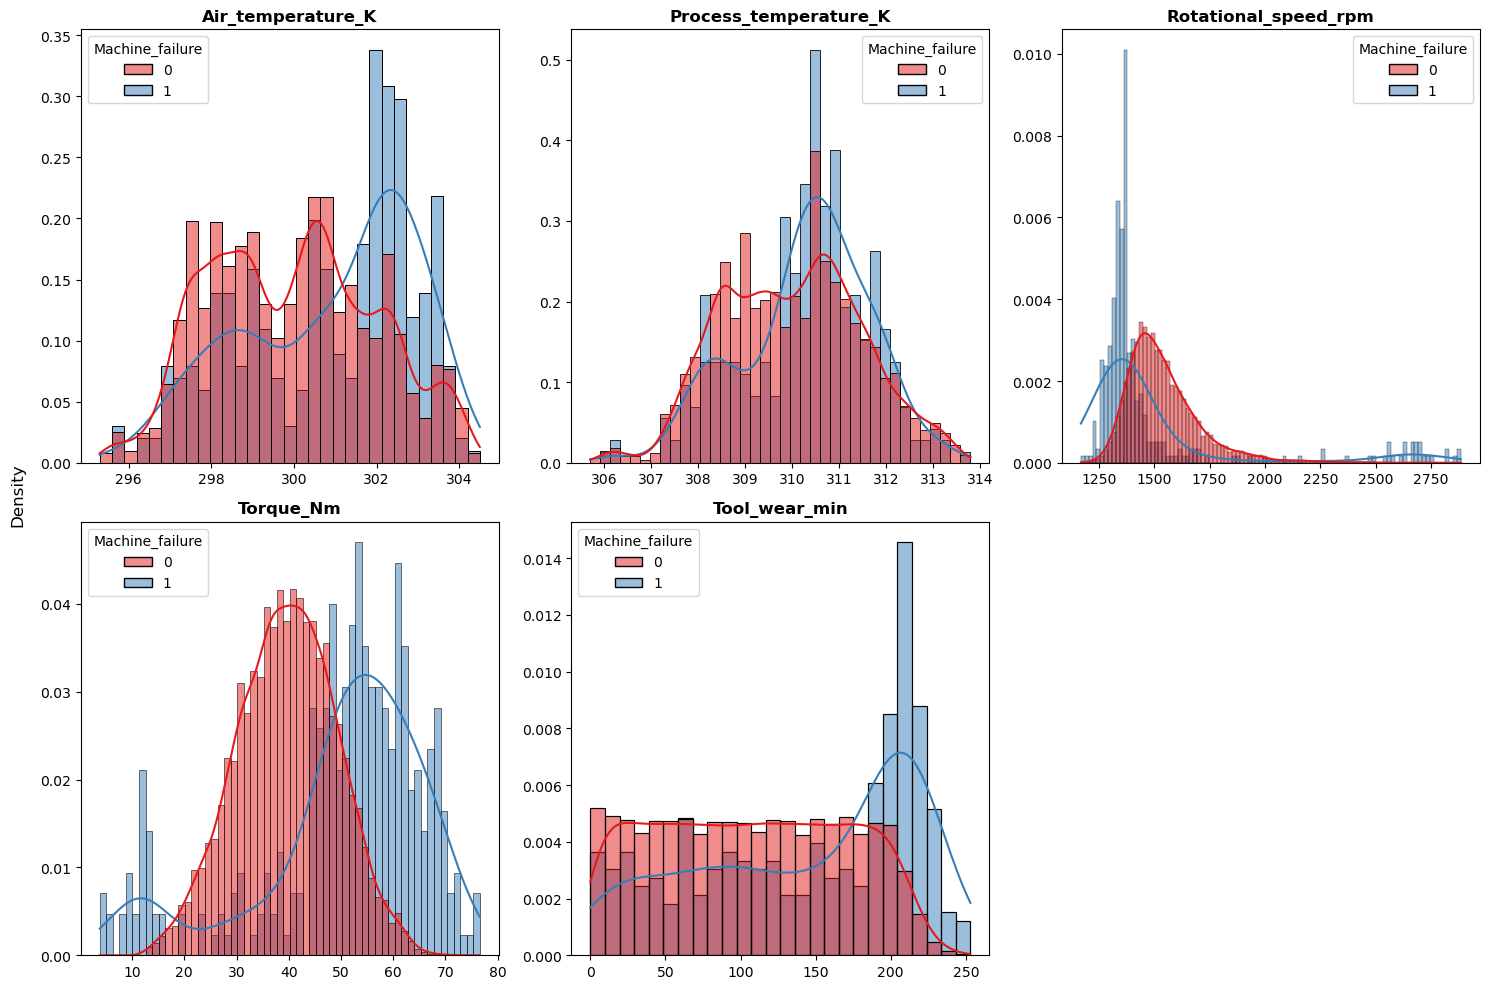

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.histplot(
        data=df, 
        x=col, 
        hue='Machine_failure', 
        kde=True, 
        stat='density',
        common_norm=False,
        palette='Set1',
        alpha=0.5,
        ax=axes[i]
    )
    
    axes[i].set_title(col, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

axes[5].axis('off')
fig.supylabel('Density', x=0.01)

plt.tight_layout()
plt.show()

3. Boxplot de las variables


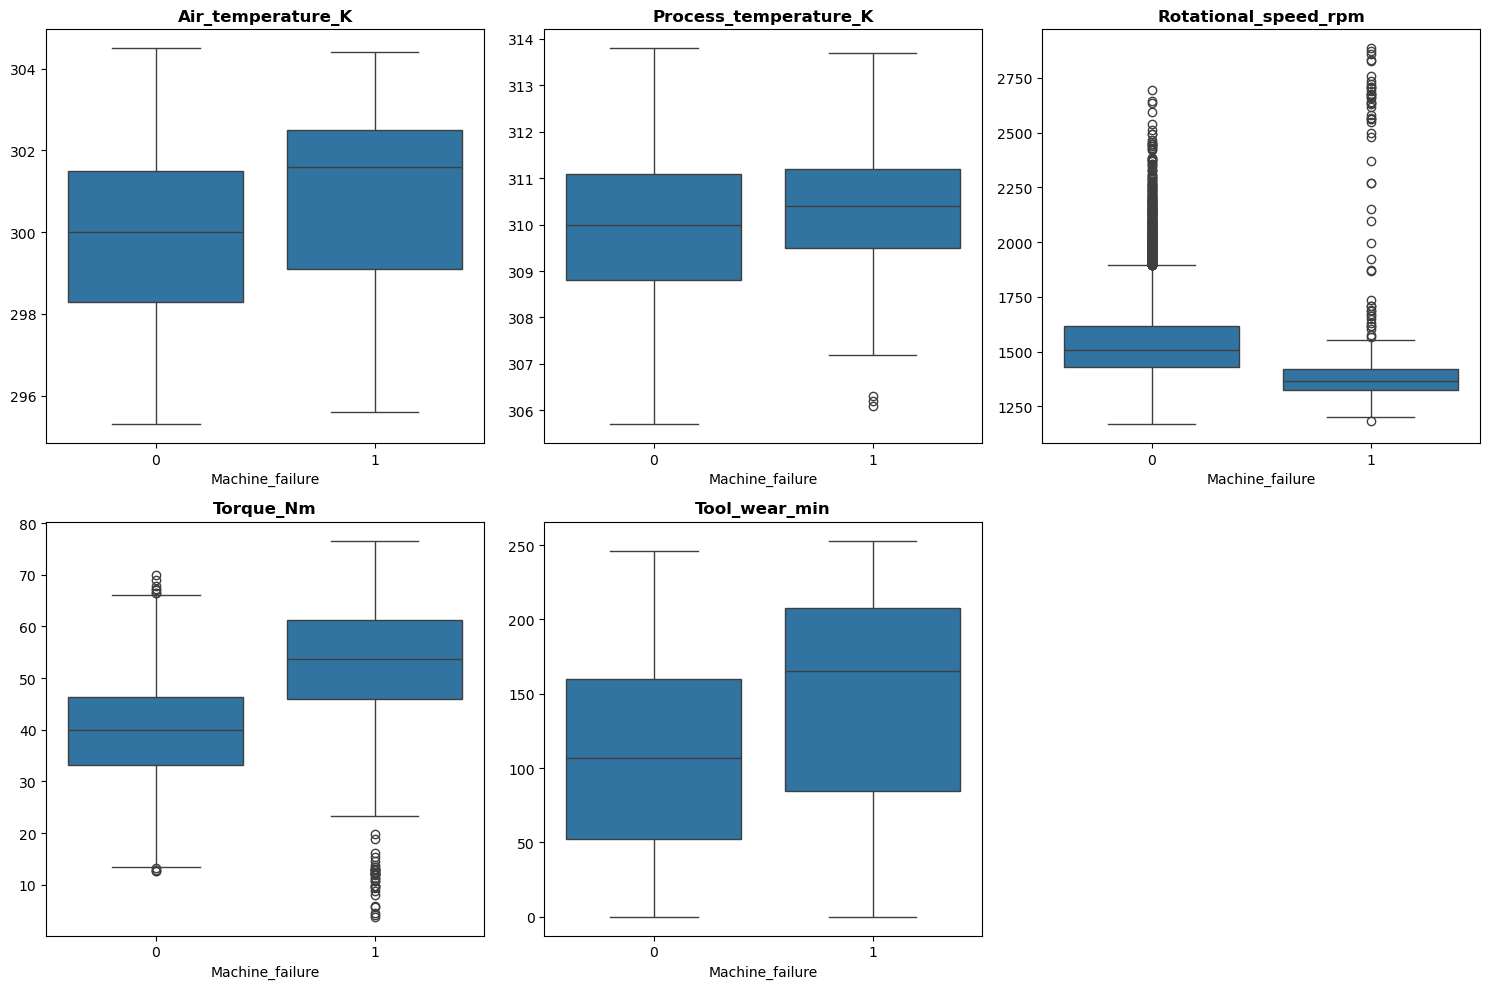

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(variables_fisicas):
    sns.boxplot(
        data=df, 
        x='Machine_failure', 
        y=col, 
        ax=axes[i]
    )

    axes[i].set_title(col, fontweight='bold')
    axes[i].set_ylabel('')

axes[5].axis('off')

plt.tight_layout()
plt.show()

Observamos tanto en los histogramas como en los boxplot, que la distribución de variables es distinta en los casos que falló la máquina. Se observa una temperatura más alta, al igual que un torque y un tiempo de uso de herramienta mayor, a su vez que la velocidad rotacional disminuye significativamente. Esta variación en las distribuciones serán las que nos servirán para entrenar a nuestro modelo predictivo


4. Análisis de la variable categórica Type

In [45]:
fallas_por_tipo = df.groupby('Type')[columnas_fallas].sum()

fallas_por_tipo['Total_Fallas'] = fallas_por_tipo.sum(axis=1)

fallas_por_tipo = fallas_por_tipo.sort_values(by='Total_Fallas', ascending=False)

display(fallas_por_tipo)

,TWF,HDF,PWF,OSF,RNF,Total_Fallas
Type,,,,,,
L,25,76,59,87,13,260
M,14,31,31,9,2,87
H,7,8,5,2,4,26


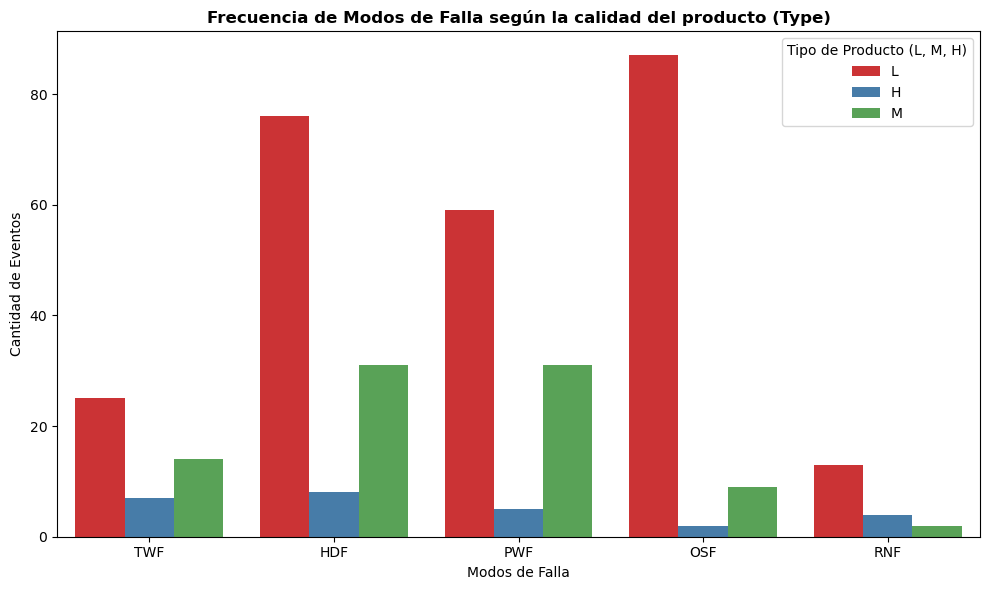

In [46]:
fallas_melt = df.melt(id_vars=['Type'],
                      value_vars=columnas_fallas,
                      var_name='Modo_Falla',
                      value_name='Ocurrencia')

fallas_positivas = fallas_melt[fallas_melt['Ocurrencia'] == 1]

plt.figure(figsize=(10,6))
sns.countplot(
    data=fallas_positivas,
    x='Modo_Falla',
    hue='Type',
    palette='Set1',
    order=columnas_fallas
)

plt.title('Frecuencia de Modos de Falla según la calidad del producto (Type)', fontweight='bold')
plt.xlabel('Modos de Falla')
plt.ylabel('Cantidad de Eventos')
plt.legend(title='Tipo de Producto (L, M, H)')
plt.tight_layout()
plt.show()

### Análisis de relaciones e hipótesis físicas

Las fallas mecánicas pueden estar asociadas con la interacción entre distintas condiciones operativas. Por este motivo, estudiaremos combinaciones de variables que permitan identificar patrones que no necesariamente se observan al analizar cada característica de forma aislada.

Se proponen las siguientes hipótesis exploratorias:

1. **Diferencia de temperaturas:** analizar si la diferencia entre la temperatura del proceso y la del aire presenta patrones distintos en los registros con y sin falla.
2. **Torque y velocidad de rotación:** estudiar la relación entre la carga mecánica y la velocidad de operación.
3. **Desgaste de herramienta y torque:** explorar si los niveles de desgaste se asocian con diferentes condiciones de esfuerzo mecánico y con una mayor proporción de fallas.
4. **Combinaciones de variables:** investigar si las fallas aparecen con mayor frecuencia en determinadas regiones del espacio de características.

Estas hipótesis se contrastarán mediante visualizaciones multivariables. Los patrones observados se interpretarán como asociaciones exploratorias, sin asumir de antemano que exista una relación causal.


Vamos a crear dos variables nuevas para investigar las combinaciones sugeridas anteriormente:

- **$\Delta T$:** diferencia entre la temperatura de proceso y la temperatura del aire.
- **$P$:** potencia mecánica aproximada, calculada a partir del torque y la velocidad angular.

La potencia se calcula mediante la siguiente expresión:

$$
P = \tau \omega = \tau \frac{2\pi n}{60}
$$

Donde:

- $\tau$: torque, expresado en newton-metro (Nm).
- $\omega$: velocidad angular, expresada en radianes por segundo (rad/s).
- $n$: velocidad de rotación, expresada en revoluciones por minuto (rpm).
- $P$: potencia mecánica aproximada, expresada en watts (W).

In [17]:
# Copia para el análisis exploratorio de relaciones físicas
df_analisis = df.copy()

# Diferencia entre temperatura de proceso y temperatura del aire
df_analisis["Temperature_difference_K"] = (
    df_analisis["Process_temperature_K"]
    - df_analisis["Air_temperature_K"]
)

# Velocidad angular en rad/s
df_analisis["Angular_speed_rad_s"] = (
    2 * np.pi * df_analisis["Rotational_speed_rpm"] / 60
)

# Potencia mecánica aproximada en watts
df_analisis["Mechanical_power_W"] = (
    df_analisis["Torque_Nm"]
    * df_analisis["Angular_speed_rad_s"]
)

display(
    df_analisis[
        [
            "Air_temperature_K",
            "Process_temperature_K",
            "Temperature_difference_K",
            "Rotational_speed_rpm",
            "Torque_Nm",
            "Mechanical_power_W",
            "Tool_wear_min",
            "Machine_failure"
        ]
    ].head()
)


,Air_temperature_K,Process_temperature_K,Temperature_difference_K,Rotational_speed_rpm,Torque_Nm,Mechanical_power_W,Tool_wear_min,Machine_failure
0,298.1,308.6,10.5,1551,42.8,6951.590560,0,0
1,298.2,308.7,10.5,1408,46.3,6826.722724,3,0
2,298.1,308.5,10.4,1498,49.4,7749.387543,5,0
3,298.2,308.6,10.4,1433,39.5,5927.504659,7,0
4,298.2,308.7,10.5,1408,40.0,5897.816608,9,0


Gráfico temperatura y velocidad

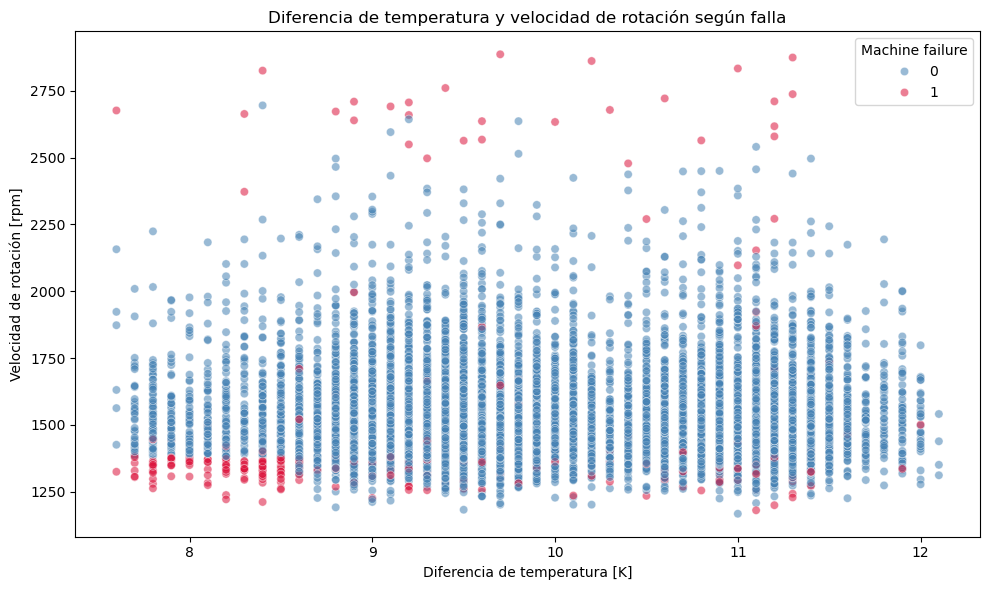

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_analisis,
    x="Temperature_difference_K",
    y="Rotational_speed_rpm",
    hue="Machine_failure",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.55
)

plt.title("Diferencia de temperatura y velocidad de rotación según falla")
plt.xlabel("Diferencia de temperatura [K]")
plt.ylabel("Velocidad de rotación [rpm]")
plt.legend(title="Machine failure")
plt.tight_layout()
plt.show()

En el gráfico se puede explorar si la combinación entre diferencia de temperaturas y velocidad de rotación separa parcialmente los registros con y sin falla. La presencia de algunos puntos de falla en una región no valida por sí sola la hipótesis; hay que evaluar cuánto se solapan las clases y comprobar el patrón con métricas y datos no usados para ajustar el modelo.

Se observa un patrón clarísimo de fallas (puntos rojos 1) en dos extremos térmicos y operativos: las velocidades muy bajas (cercanas a 1250 rpm) y las zonas con alta diferencia de temperatura. Esto valida completamente su Hipótesis 1.


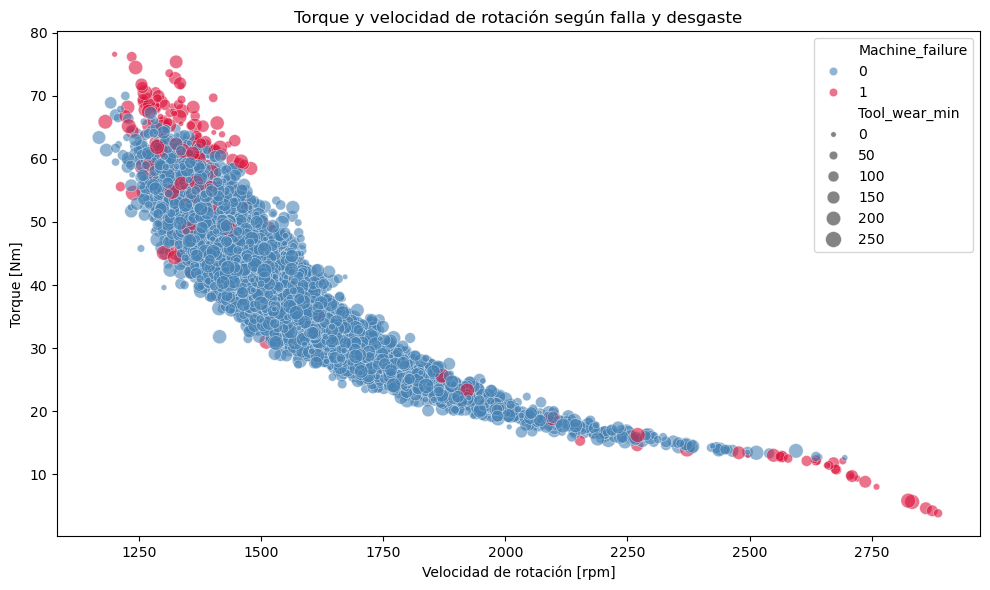

In [19]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_analisis,
    x="Rotational_speed_rpm",
    y="Torque_Nm",
    hue="Machine_failure",
    size="Tool_wear_min",
    sizes=(15, 130),
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.6,
    legend="brief"
)

plt.title("Torque y velocidad de rotación según falla y desgaste")
plt.xlabel("Velocidad de rotación [rpm]")
plt.ylabel("Torque [Nm]")
plt.tight_layout()
plt.show()

El gráfico permite explorar conjuntamente torque, velocidad y desgaste de herramienta. Si las fallas aparecen concentradas en ciertas regiones, eso puede orientar la ingeniería de características y la selección de modelos. No conviene afirmar que una región es “de riesgo” sin cuantificar la tasa de falla por región y considerar el bajo número de casos positivos.

Las fallas se concentran fuertemente en el extremo superior izquierdo (Torque muy alto y Velocidad baja) y algunas en el extremo inferior derecho (Velocidad muy alta con Torque bajo, combinado con un desgaste de herramienta grande por el tamaño de las burbujas).


--- PRUEBA DE NORMALIDAD (SHAPIRO-WILK) ---
Variable 'Air_temperature_K': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Process_temperature_K': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Temperature_difference_K': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Rotational_speed_rpm': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Torque_Nm': p-value = 0.40797
  -> Sigue una distribución Normal (Acepta H0)
Variable 'Mechanical_power_W': p-value = 0.00012
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Tool_wear_min': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Variable 'Type_encoded': p-value = 0.00000
  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)
Va

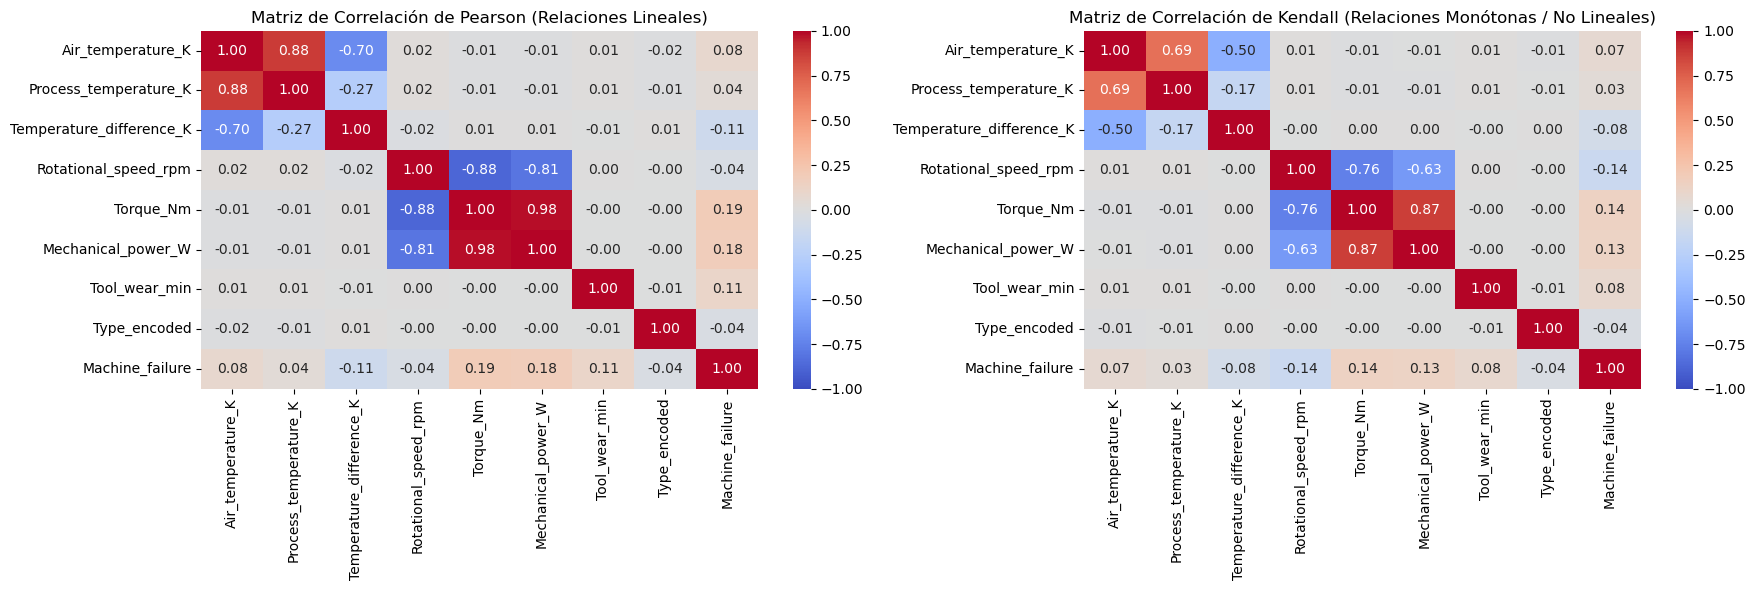

In [47]:
# Mapeamos la variable categórica ordinal a valores numéricos asumiendo jerarquía
df_analisis['Type_encoded'] = df_analisis['Type'].map({'L': 1, 'M': 2, 'H': 3})

# Seleccionamos las variables numéricas, la nueva ordinal codificada y el target
variables_correlacion = [
    "Air_temperature_K", "Process_temperature_K", "Temperature_difference_K",
    "Rotational_speed_rpm", "Torque_Nm", "Mechanical_power_W", "Tool_wear_min", 
    "Type_encoded", "Machine_failure"
]

df_num = df_analisis[variables_correlacion]

# Análisis de distribución y normalidad
print("--- PRUEBA DE NORMALIDAD (SHAPIRO-WILK) ---")
# Nota: Shapiro-Wilk tiene un límite de 5000 registros en algunas librerías, 
# tomamos una muestra representativa para evaluar la forma.
df_sample = df_num.sample(min(4000, len(df_num)), random_state=42)

for col in variables_correlacion:
    stat, p_value = shapiro(df_sample[col])
    print(f"Variable '{col}': p-value = {p_value:.5f}")
    if p_value > 0.05:
        print(f"  -> Sigue una distribución Normal (Acepta H0)")
    else:
        print(f"  -> NO sigue una distribución Normal (Rechaza H0 - Usar Kendall/Spearman)")


# 2. CÁLCULO DE CORRELACIONES (PEARSON VS KENDALL)

# Dado que la velocidad y el torque muestran una clara relación NO lineal (curva),
# la correlación de Pearson subestimará su fuerza. Usamos Kendall.

plt.figure(figsize=(18, 6))

# Matriz Pearson
plt.subplot(1, 2, 1)
corr_pearson = df_num.corr(method='pearson')
sns.heatmap(corr_pearson, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación de Pearson (Relaciones Lineales)")

# Matriz Kendall
plt.subplot(1, 2, 2)
corr_kendall = df_num.corr(method='kendall')
sns.heatmap(corr_kendall, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matriz de Correlación de Kendall (Relaciones Monótonas / No Lineales)")

plt.tight_layout()
plt.show()


Las correlaciones entre `Torque_Nm` y `Mechanical_power_W`, así como entre las temperaturas y `Temperature_difference_K`, son dependencias inyectadas por el feature engineering- 

El target `Machine_failure` mantiene correlaciones muy débiles con todas las métricas físicas. Esto demuestra que la maquinaria no colapsa por un deterioro lineal aislado, sino por cruzar umbrales termodinámicos o mecánicos críticos, o por combinaciones multivariadas más complejas.

La relación inversa entre `Rotational_speed_rpm` y `Torque_Nm` es bastante marcada. Esto también se observa en el scatterplot celdas más arriba.

In [ ]:
# 3. CLUSTERING NO SUPERVISADO (MÉTODO DEL CODO)

# Para clustering es obligatorio escalar las variables para no sesgar por magnitudes
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_num)

inercia = []
valores_k = range(1, 9)

for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)

# Graficar el Método del Codo
plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercia, marker='o', color='purple', linestyle='--')
plt.title("Método del Codo para Identificar Grupos Naturales")
plt.xlabel("Número de Clusters (K)")
plt.ylabel("Inercia (WCSS)")
plt.grid(True)
plt.show()

## Planteamiento del problema de Machine Learning

### Objetivo del modelo

El objetivo de esta etapa es desarrollar un modelo de aprendizaje automático supervisado capaz de predecir la ocurrencia de una falla mecánica a partir de las características físicas y operativas de una máquina.

Se plantea un problema de **clasificación binaria**, en el que la variable objetivo es `Machine_failure`:

- **Clase 0:** no se registra una falla de la máquina.
- **Clase 1:** se registra una falla de la máquina.

### Variables predictoras y variable objetivo

Por convención, se utilizará \(X\) para representar la matriz de variables predictoras e \(y\) para representar la variable objetivo.

Las variables predictoras iniciales serán:

- `Type`: tipo de producto (L, M o H).
- `Air temperature [K]`: temperatura del aire.
- `Process temperature [K]`: temperatura del proceso.
- `Rotational speed [rpm]`: velocidad de rotación.
- `Torque [Nm]`: torque.
- `Tool wear [min]`: desgaste acumulado de la herramienta.

Se excluirán los identificadores `UDI` y `Product ID`, ya que identifican registros o productos y no constituyen, en principio, mediciones físicas que permitan anticipar una falla.

También se excluirán las columnas `TWF`, `HDF`, `PWF`, `OSF` y `RNF` de las variables predictoras. Estas representan etiquetas de modos de falla registradas en el dataset y su utilización podría introducir fuga de información (*data leakage*) al intentar predecir `Machine failure`.

### Limitaciones del problema

El dataset presenta un fuerte desbalance de clases: aproximadamente el 96,61 % de los registros corresponde a la clase 0 y el 3,39 % a la clase 1. Por lo tanto, la exactitud global no será suficiente para evaluar la utilidad del modelo.

Además, el dataset contiene una categoría de falla aleatoria (`RNF`), que no debe interpretarse como un fenómeno necesariamente predecible a partir de las variables físicas disponibles. Esto constituye una limitación potencial para la predicción de todas las fallas registradas.

Finalmente, las asociaciones encontradas entre las variables y las fallas no demuestran causalidad. El análisis permitirá identificar patrones y evaluar capacidad predictiva, pero no establecer por sí solo relaciones causales.

### Preparación y Preprocesamiento de Datos


Aplicamos OneHotEncoder a la variable categórica type y standardscaler a las variables numéricas

In [27]:
# Identificar los tipos de variables
variables_categoricas = ["Type"]

variables_numericas = [
    "Air_temperature_K",
    "Process_temperature_K",
    "Rotational_speed_rpm",
    "Torque_Nm",
    "Tool_wear_min"
]

# Transformaciones para cada tipo de variable
preprocesamiento = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            variables_categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            variables_numericas
        )
    ],
    remainder="drop"
)

print("Variables categóricas:", variables_categoricas)
print("Variables numéricas:", variables_numericas)


Variables categóricas: ['Type']
Variables numéricas: ['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min']


In [28]:
X = df[
    variables_categoricas + variables_numericas
]

y = df["Machine_failure"]

Debido al severo desbalance de clases (3.39% de fallas), la división de los datos se realizará utilizando una estrategia estratificada. Esto garantiza que tanto el conjunto de entrenamiento (X_train, y_train) como el de prueba (X_test, y_test) mantengan exactamente la misma proporción de máquinas operativas y falladas, evitando evaluaciones sesgadas.

In [29]:
# Dividimos en 80% entrenamiento y 20% prueba de forma estratificada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.20, 
    stratify=y, 
    random_state=42
)

print(f"Registros en Training: {X_train.shape[0]} | Proporción de fallas: {y_train.mean():.4f}")
print(f"Registros en Testing:  {X_test.shape[0]} | Proporción de fallas: {y_test.mean():.4f}")

Registros en Training: 8000 | Proporción de fallas: 0.0339
Registros en Testing:  2000 | Proporción de fallas: 0.0340


### Pipeline de regresión logística

In [30]:
pipeline_logistica = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("smote", SMOTE(random_state=42)),
    ("modelo", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

**Optimización de regresión logística**

In [31]:
parametros_logistica = {
    "modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "modelo__penalty": ["l2"],
    "modelo__solver": ["lbfgs", "liblinear"],
    "modelo__class_weight": [None, "balanced"]
}

In [32]:
busqueda_logistica = RandomizedSearchCV(
    estimator=pipeline_logistica,
    param_distributions=parametros_logistica,
    n_iter=15,
    scoring="recall",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True
)

busqueda_logistica.fit(X_train, y_train)

Fitting 5 folds for each of 15 candidates, totalling 75 fits


KeyboardInterrupt: 

### Pipeline de XGBoost

In [118]:
pipeline_xgboost = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("smote", SMOTE(random_state=42)),
    ("modelo", xgb.XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        tree_method="hist",
        n_jobs=-1
    ))
])

parametros_xgboost = {
    "modelo__n_estimators": [100, 200, 300, 500],
    "modelo__max_depth": [2, 3, 4, 5, 6, 8],
    "modelo__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "modelo__subsample": [0.7, 0.8, 0.9, 1.0],
    "modelo__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "modelo__min_child_weight": [1, 3, 5, 10],
    "modelo__gamma": [0, 0.1, 0.3, 0.5],
    "modelo__reg_alpha": [0, 0.01, 0.1, 1],
    "modelo__reg_lambda": [1, 2, 5, 10]
}

busqueda_xgboost = RandomizedSearchCV(
    estimator=pipeline_xgboost,
    param_distributions=parametros_xgboost,
    n_iter=100,
    scoring="recall",
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    refit=True
)

busqueda_xgboost.fit(X_train, y_train)

Fitting 5 folds for each of 100 candidates, totalling 500 fits


RandomizedSearchCV(cv=5,
                   estimator=Pipeline(steps=[('preprocesamiento',
                                              ColumnTransformer(transformers=[('categoricas',
                                                                               OneHotEncoder(handle_unknown='ignore'),
                                                                               ['Type']),
                                                                              ('numericas',
                                                                               StandardScaler(),
                                                                               ['Air_temperature_K',
                                                                                'Process_temperature_K',
                                                                                'Rotational_speed_rpm',
                                                                                'Torque_Nm',
                                                                                'Tool_wear_min'])])),
                                             ('smote', SMOTE(random_state=42)),
                                             ('modelo',
                                              XGBClassif...
                                                                     0.9, 1.0],
                                        'modelo__gamma': [0, 0.1, 0.3, 0.5],
                                        'modelo__learning_rate': [0.01, 0.03,
                                                                  0.05, 0.1,
                                                                  0.2],
                                        'modelo__max_depth': [2, 3, 4, 5, 6, 8],
                                        'modelo__min_child_weight': [1, 3, 5,
                                                                     10],
                                        'modelo__n_estimators': [100, 200, 300,
                                                                 500],
                                        'modelo__reg_alpha': [0, 0.01, 0.1, 1],
                                        'modelo__reg_lambda': [1, 2, 5, 10],
                                        'modelo__subsample': [0.7, 0.8, 0.9,
                                                              1.0]},
                   random_state=42, scoring='recall', verbose=2)

**Evaluación de regresión logística**

In [120]:
modelo_logistica = busqueda_logistica.best_estimator_

y_pred_logistica = modelo_logistica.predict(X_test)
y_prob_logistica = modelo_logistica.predict_proba(X_test)[:, 1]

print("===== REGRESIÓN LOGÍSTICA =====")
print(classification_report(
    y_test,
    y_pred_logistica,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_logistica))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_logistica))

print("Average Precision:",
      average_precision_score(y_test, y_prob_logistica))

===== REGRESIÓN LOGÍSTICA =====
              precision    recall  f1-score   support

           0       0.99      0.76      0.86      1932
           1       0.11      0.87      0.20        68

    accuracy                           0.77      2000
   macro avg       0.55      0.81      0.53      2000
weighted avg       0.96      0.77      0.84      2000

Matriz de confusión:
[[1472  460]
 [   9   59]]
ROC-AUC: 0.8968304713189624
Average Precision: 0.32823777006262456


**Evaluación de XGBoost**

In [121]:
modelo_xgboost = busqueda_xgboost.best_estimator_

y_pred_xgboost = modelo_xgboost.predict(X_test)
y_prob_xgboost = modelo_xgboost.predict_proba(X_test)[:, 1]

print("===== XGBOOST =====")
print(classification_report(
    y_test,
    y_pred_xgboost,
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgboost))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgboost))

print("Average Precision:",
      average_precision_score(y_test, y_prob_xgboost))

===== XGBOOST =====
              precision    recall  f1-score   support

           0       1.00      0.92      0.95      1932
           1       0.27      0.91      0.42        68

    accuracy                           0.92      2000
   macro avg       0.64      0.91      0.69      2000
weighted avg       0.97      0.92      0.94      2000

Matriz de confusión:
[[1768  164]
 [   6   62]]
ROC-AUC: 0.9461126842041164
Average Precision: 0.5716890435413415


In [122]:
comparacion = pd.DataFrame({
    "modelo": [
        "Regresión logística",
        "XGBoost"
    ],
    "precision_clase_1": [
        precision_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "recall_clase_1": [
        recall_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "f1_clase_1": [
        f1_score(
            y_test,
            y_pred_logistica,
            zero_division=0
        ),
        f1_score(
            y_test,
            y_pred_xgboost,
            zero_division=0
        )
    ],
    "roc_auc": [
        roc_auc_score(y_test, y_prob_logistica),
        roc_auc_score(y_test, y_prob_xgboost)
    ],
    "average_precision": [
        average_precision_score(y_test, y_prob_logistica),
        average_precision_score(y_test, y_prob_xgboost)
    ]
})

comparacion

,modelo,precision_clase_1,recall_clase_1,f1_clase_1,roc_auc,average_precision
0,Regresión logística,0.113680,0.867647,0.201022,0.896830,0.328238
1,XGBoost,0.274336,0.911765,0.421769,0.946113,0.571689


La comparación muestra que ambos modelos logran detectar una proporción elevada de las fallas, aunque presentan diferencias importantes en su desempeño. La regresión logística alcanza un recall de la clase 1 de 0,868, lo que significa que identifica aproximadamente el 87 % de las fallas reales. Sin embargo, su precisión es baja (0,114), por lo que genera una cantidad considerable de falsas alarmas. Esto se refleja en un F1-score de apenas 0,201.

XGBoost presenta un mejor desempeño en todas las métricas analizadas. Alcanza un recall de 0,912, detectando aproximadamente el 91 % de las fallas reales, y obtiene una precisión de 0,274. Si bien todavía produce falsas alarmas, la proporción de alertas correctas es mayor que en la regresión logística. Además, su F1-score es 0,422, más del doble que el obtenido por la regresión logística.